In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/raw/loans.csv')
print(df.shape)
df.info()
df.describe()

(614, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [2]:
print(df.isna().sum())
print('Duplicate rows:', df.duplicated().sum())

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64
Duplicate rows: 0


Loan_Status
Y    0.687296
N    0.312704
Name: proportion, dtype: float64


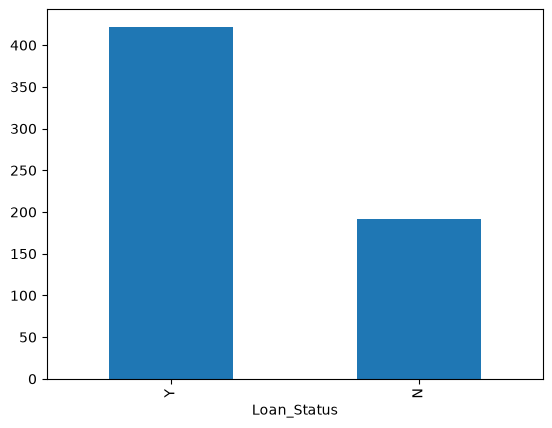

In [3]:
print(df['Loan_Status'].value_counts(normalize=True))
df['Loan_Status'].value_counts().plot.bar()
plt.show()

In [4]:
df['approved'] = (df['Loan_Status'] == 'Y').astype(int)
for col in ['Credit_History', 'Property_Area', 'Education', 'Married', 'Self_Employed', 'Dependents']:
    print(df.groupby(col)['approved'].mean().round(2), '\n')

Credit_History
0.0    0.08
1.0    0.80
Name: approved, dtype: float64 

Property_Area
Rural        0.61
Semiurban    0.77
Urban        0.66
Name: approved, dtype: float64 

Education
Graduate        0.71
Not Graduate    0.61
Name: approved, dtype: float64 

Married
No     0.63
Yes    0.72
Name: approved, dtype: float64 

Self_Employed
No     0.69
Yes    0.68
Name: approved, dtype: float64 

Dependents
0     0.69
1     0.65
2     0.75
3+    0.65
Name: approved, dtype: float64 



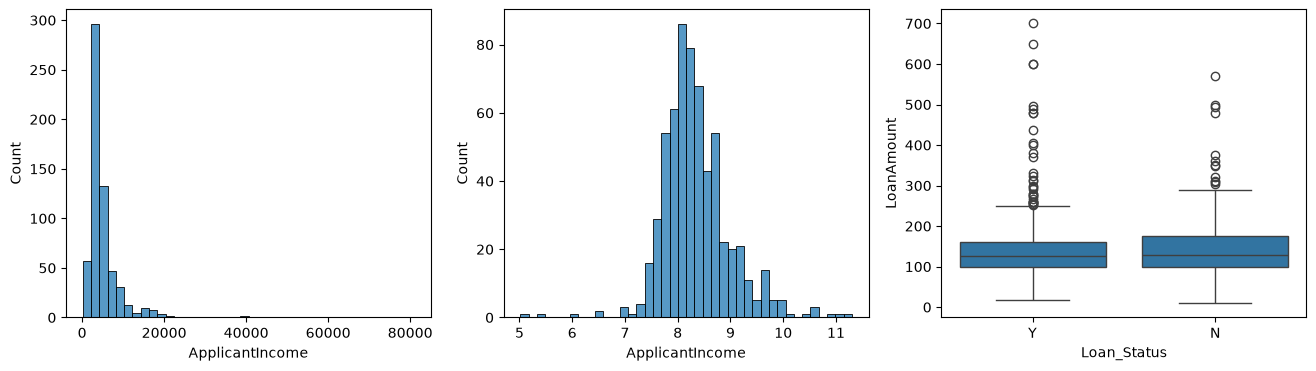

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['ApplicantIncome'], bins=40, ax=ax[0])
sns.histplot(np.log1p(df['ApplicantIncome']), bins=40, ax=ax[1])
sns.boxplot(data=df, x='Loan_Status', y='LoanAmount', ax=ax[2])
plt.show()